# **Un study of interaction between weather, groundwater and surface streamflow in the South of France**

Thank you so much for your help ! It was very helpful I feel like I really move forward this week thanks to you but I still have major issues with the results! I also have question regarding the interpretation of my results but I am not sure if we can discuss about it. If you have any issue running the code or on the larger context of the project let me know :)

NB : At some point of this notebook I put images of the results in the case that the code is too long to run but now everything should run in approximately **an hour !!!** 

![title](img/carte.png)

## Choice of reprocess

In [1]:
import import_function as fun 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from pyEDM import *
from CyNLA import CyNLA
dx = CyNLA.dx
from seaborn import heatmap, kdeplot, histplot, color_palette

# R functions
import os
os.environ["R_LIBS_USER"] = os.path.expanduser("~/R/library")
from rpy2.robjects.packages import importr
detectBatch = importr('cpm').detectChangePointBatch
rdollar     = importr('base').__dict__['$']
import warnings
from rpy2.rinterface import RRuntimeWarning
warnings.filterwarnings("ignore", category=RRuntimeWarning)
import os, string
import CyNLA
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

print(CyNLA.__file__)
print([n for n in dir(CyNLA) if not n.startswith('__')])


/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


None
['CyNLA']


In [2]:
fdv1 = pd.read_csv('donnees/rivers_02-13.csv', sep=';', parse_dates=['date'])
fdv1 = fdv1[(fdv1['city']=='FONTAINE DE VAUCLUSE 1') & (fdv1['date'] > '2004-01-01')]
river_flow = fun.normalize_series(fdv1['mean_flow'])
detrended_river = fun.detrend_add(river_flow)
deseasoned_river = fun.deseason_mult(detrended_river, 1) #1 for annual
fdv1['mean_flow'] = deseasoned_river


meteo = pd.read_csv('donnees/meteo_02-13.csv', sep = ';', parse_dates=['date'])
meteo = meteo[(meteo['city'] == 'ISLE SUR SORGUE') & (meteo['date'] > '2004-01-01')]
rain = fun.normalize_series(meteo['precipitation'])
detrended_rain = fun.detrend_add(rain)
deseasoned_rain = fun.deseason_add(detrended_rain, 1)
meteo['precipitation'] = deseasoned_rain

ground_water = pd.read_csv('donnees/groundwater_02-13.csv', sep=';', parse_dates = ['date'])
ground_water = ground_water[(ground_water['city']=='THOR') & (ground_water['date'] > '2004-01-01')]
depth = fun.normalize_series(ground_water['NGF_depth'])
detrended_depth = fun.detrend_add(depth)
deseasoned_depth = fun.deseason_add(detrended_depth, 1)
ground_water['NGF_depth'] = deseasoned_depth

## CCM Algorithm (non preprocess (except for normalisation) datas are mostly used here : see article placed in reference for detail)

I am having some  struggle to choose the right values for the parameters in ccm : 
- how many sample should I choose for each run of ccm ? I have chosen sample = 5 for the moment as you can see in import_function.py but it is purely arbitrary
- when the seed should be changed/kept regarding the effect on accuracy and reproductability ? for the moment I have one seed for computing the best embedding dimension and then one seed for the final run of ccm so my result is not biased but I have reproductability when choosing the best emebedding dimension
- how should I compute the best embedding dimension ? is it more accurate to compute it with simplex or ccm directly ? if it is with ccm how can I choose Tp : 0 because instant cross-map, -1 for hint cast or the optimum for rho ? for the moment I computing with ccm and Tp=-1 because I heard that it is the more relevant but I don't know why.  

E causal =  4
E non causal =  5


(0.0, 1.0)

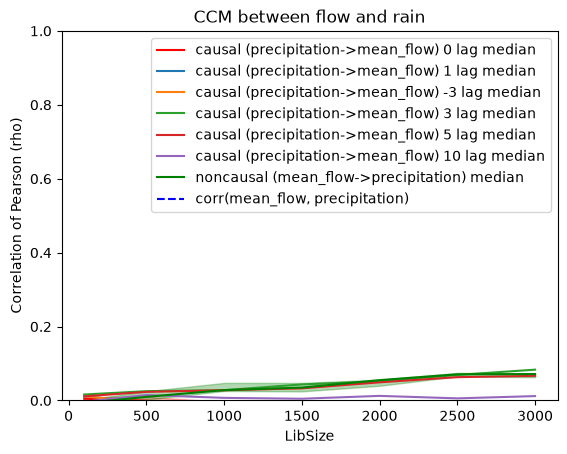

In [3]:
df = (
    pd.merge(
        meteo[['date', 'precipitation']].dropna(),
        fdv1[['date', 'mean_flow']].dropna(),
        on='date',
        how='inner'
    )
    .sort_values('date')
    .reset_index(drop=True)
)

df = df[['date', 'precipitation', 'mean_flow']].dropna().reset_index(drop=True)

E_best_causal = fun.find_best_E_ccm(df, 'mean_flow', 'precipitation')
print('E causal = ', E_best_causal)
E_best_noncausal = fun.find_best_E_ccm(df, 'precipitation', 'mean_flow')
print('E non causal = ', E_best_noncausal)

libs = [100, 500, 1000, 1500, 2000, 2500, 3000]

causal = fun.run_ccm_bootstrap(df, 'mean_flow', 'precipitation', E_best_causal, libs=libs)
non_causal = fun.run_ccm_bootstrap(df, 'precipitation', 'mean_flow', E_best_noncausal, libs=libs)


final_causal0 = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=0)
final_causal1 = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=-3)
final_causal2 = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp= 1)
final_causal3 = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=-3)
final_causal5 = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=-5)
final_causal10 = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=-10)
final_noncausal = fun.final_ccm(df, 'precipitation', 'mean_flow', libs=libs)


stat_causal0 = final_causal0[0]
stat_causal1 = final_causal1[0]
stat_causal2 = final_causal2[0]
stat_causal3 = final_causal3[0]
stat_causal5 = final_causal5[0]
stat_causal10 = final_causal10[0]
stat_noncausal = final_noncausal[0]

libsize = stat_causal0.index

corr0 = df['mean_flow'].corr(df['precipitation'])

plt.figure()
plt.plot(libsize, stat_causal0[0.5], color='r', label= 'causal (precipitation->mean_flow) 0 lag' + " median")
plt.fill_between(libsize, stat_causal0[0.25], stat_causal0[0.75], color='r', alpha=0.3)
plt.plot(libsize, stat_causal2[0.5], label= 'causal (precipitation->mean_flow) 1 lag' + " median")
plt.plot(libsize, stat_causal2[0.5], label= 'causal (precipitation->mean_flow) -3 lag' + " median")
plt.plot(libsize, stat_causal3[0.5], label= 'causal (precipitation->mean_flow) 3 lag' + " median")
plt.plot(libsize, stat_causal5[0.5], label= 'causal (precipitation->mean_flow) 5 lag' + " median")
plt.plot(libsize, stat_causal10[0.5],label= 'causal (precipitation->mean_flow) 10 lag' + " median")
plt.plot(libsize, stat_noncausal[0.5], color='g', label= 'noncausal (mean_flow->precipitation)' + " median")
plt.fill_between(libsize, stat_noncausal[0.25], stat_noncausal[0.75], color='g', alpha=0.3)
plt.axhline(corr0, color='b', linestyle='--', label=f"corr(mean_flow, precipitation)")
plt.title('CCM between flow and rain')
plt.xlabel('LibSize')
plt.ylabel('Correlation of Pearson (rho)')
plt.legend()
plt.ylim(0,1)

## this is very strange because it seems that there is a causality mean_flow --> precipitation instead of precipitation --> mean_flow
# even though we are using different kind of preprocessing
# an explanation could be : artefact/error in the code, lack in the data (particularly a lot of 0 in precipitation data) or delay between precipitation and variation of mean_flow
# so I can also try to implement delay to but I am not sure how to do it --> need to read the last article

#with 3 days lag dand without preprocess result seems statisfying but we now need to quantify thsi result thanks to surrogate and pvalue

![title](img/ccm_lag.png)

    Groundwater <-> streamflow

In [ ]:
df = pd.merge(fdv1[['date', 'mean_flow']], ground_water[['date', 'NGF_depth']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df = df[['date', 'mean_flow', 'NGF_depth']].dropna().reset_index(drop=True)
libs = [100, 500, 1000, 1500, 2000, 2500, 3000]

E_best_infiltration = fun.find_best_E_ccm(df, 'NGF_depth', 'mean_flow')
E_best_saturation = fun.find_best_E_ccm(df, 'mean_flow', 'NGF_depth')

infiltration = fun.run_ccm_bootstrap(df, 'NGF_depth', 'mean_flow', E_best_infiltration, libs=libs)
saturation = fun.run_ccm_bootstrap(df, 'mean_flow', 'NGF_depth', E_best_saturation, libs=libs)


final_infiltration0 = fun.final_ccm(df, 'NGF_depth', 'mean_flow', libs=libs, Tp=0)
final_infiltration5 = fun.final_ccm(df, 'NGF_depth', 'mean_flow', libs=libs, Tp=-5)
final_infiltration10 = fun.final_ccm(df, 'NGF_depth', 'mean_flow', libs=libs, Tp=-10)
final_infiltration30 = fun.final_ccm(df, 'NGF_depth', 'mean_flow', libs=libs, Tp=-30)

final_saturation0 = fun.final_ccm(df, 'mean_flow', 'NGF_depth', libs=libs, Tp=0)
final_saturation5 = fun.final_ccm(df, 'mean_flow', 'NGF_depth', libs=libs, Tp=-5)
final_saturation10 = fun.final_ccm(df, 'mean_flow', 'NGF_depth', libs=libs, Tp=-10)
final_saturation30 = fun.final_ccm(df, 'mean_flow', 'NGF_depth', libs=libs, Tp=-30)


stat_infiltration0 = final_infiltration0[0]
stat_infiltration5 = final_infiltration5[0]
stat_infiltration10 = final_infiltration10[0]
stat_infiltration30 = final_infiltration30[0]

stat_saturation0 = final_saturation0[0]
stat_saturation5 = final_saturation5[0]
stat_saturation10 = final_saturation10[0]
stat_saturation30 = final_saturation30[0]

libsize = stat_infiltration0.index

corr0 = df['mean_flow'].corr(df['NGF_depth'])

plt.figure()
plt.plot(libsize, stat_infiltration0[0.5], color='r', label= 'causal (mean_flow->ground_water height) 0 lag' + " median")
plt.plot(libsize, stat_infiltration5[0.5], label= 'causal (mean_flow->ground_water height) 5 lag' + " median")
plt.plot(libsize, stat_infiltration10[0.5],label= 'causal (mean_flow->ground_water height) 10 lag' + " median")
plt.plot(libsize, stat_infiltration30[0.5],label= 'causal (mean_flow->ground_water height) 30 lag' + " median")
plt.axhline(corr0, color='b', linestyle='--', label=f"corr(mean_flow, precipitation)")
plt.title('CCM between river flow -> ground water')
plt.xlabel('LibSize')
plt.ylabel('Correlation of Pearson (rho)')
plt.legend()
plt.ylim(0,1)


plt.figure()
plt.plot(libsize, stat_saturation0[0.5], color='r', label= 'causal (groundwater height -> mean flow) 0 lag' + " median")
plt.plot(libsize, stat_saturation5[0.5], label= 'causal (groundwater height -> mean flow) 5 lag' + " median")
plt.plot(libsize, stat_saturation10[0.5],label= 'causal (groundwater height -> mean flow) 10 lag' + " median")
plt.plot(libsize, stat_saturation30[0.5],label= 'causal (groundwater height -> mean flow) 30 lag' + " median")
plt.axhline(corr0, color='b', linestyle='--', label=f"corr(mean_flow, precipitation)")
plt.title('CCM between groundwater -> river flow')
plt.xlabel('LibSize')
plt.ylabel('Correlation of Pearson (rho)')
plt.legend()
plt.ylim(0,1)

![title](img/ccm_groundwater_lag.png)
![title](img/ccm_groundwater_reverse.png)

**Different time steps**

I run the code with monthly data as you suggested last time but it seems that the correlation is less important than with the daily data so I didn't to pursue the idea but I should work a bit more one it by computing surrogate and interaction strenght

(0.0, 1.0)

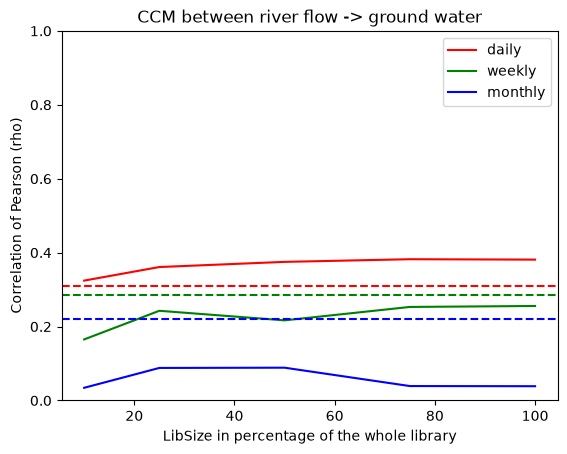

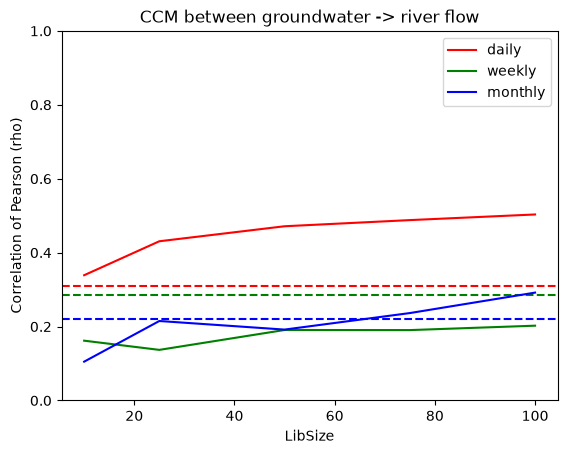

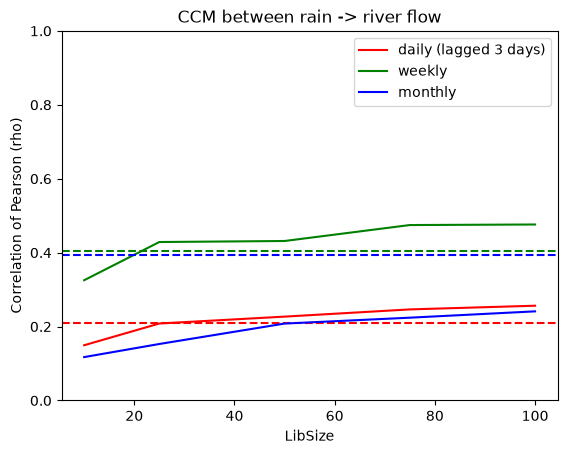

In [ ]:
df = pd.merge(fdv1[['date', 'mean_flow']], meteo[['date', 'precipitation']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df['lag_precipitation'] = pd.Series([None,None,None]+list(df['precipitation']))
df = pd.merge(df, ground_water[['date', 'NGF_depth']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df = df[['date', 'mean_flow', 'NGF_depth', 'precipitation', 'lag_precipitation']].dropna().reset_index(drop=True)
df = df.copy()
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

df_week = df.resample('W', on='date').agg({
    'mean_flow': 'mean',
    'precipitation': 'sum',
    'lag_precipitation': 'sum',
    'NGF_depth': 'mean'
}).reset_index()
df_week['mean_flow'] = fun.normalize_series(df_week['mean_flow'])
df_week['precipitation'] = fun.normalize_series(df_week['precipitation'])
df_week['lag_precipitation'] = fun.normalize_series(df_week['lag_precipitation'])
df_week['NGF_depth'] = fun.normalize_series(df_week['NGF_depth'])

df_month = df.resample('ME', on='date').agg({
    'mean_flow': 'mean',
    'precipitation': 'sum',
    'lag_precipitation': 'sum',
    'NGF_depth': 'mean'
}).reset_index()
df_month['mean_flow'] = fun.normalize_series(df_month['mean_flow'])
df_month['precipitation'] = fun.normalize_series(df_month['precipitation'])
df_month['lag_precipitation'] = fun.normalize_series(df_month['lag_precipitation'])
df_month['NGF_depth'] = fun.normalize_series(df_month['NGF_depth'])

df['date'] = df['date'].dt.strftime('%Y-%m-%d')
df_week['date'] = df_week['date'].dt.strftime('%Y-%m-%d')
df_month['date'] = df_month['date'].dt.strftime('%Y-%m-%d')

libs = [10, 25, 50, 75, 100]

libs_daily = [300, 750, 1500, 2250, 3000]
final_infiltration0 = fun.final_ccm(df, 'NGF_depth', 'mean_flow', libs=libs_daily, Tp=0)
final_saturation0 = fun.final_ccm(df, 'mean_flow', 'NGF_depth', libs=libs_daily, Tp=0)
stat_infiltration = final_infiltration0[0]
stat_saturation = final_saturation0[0]
corr = df['mean_flow'].corr(df['NGF_depth'])
final_causal = fun.final_ccm(df, 'mean_flow', 'lag_precipitation', libs=libs_daily, Tp=-3)
stat_causal = final_causal[0]
corr_causal = df['mean_flow'].corr(df['lag_precipitation'])

libs_weekly = [50, 125, 250, 375, 450]
final_infiltration0 = fun.final_ccm(df_week, 'NGF_depth', 'mean_flow', libs=libs_weekly, Tp=0)
final_saturation0 = fun.final_ccm(df_week, 'mean_flow', 'NGF_depth', libs=libs_weekly, Tp=0)
stat_infiltration_week = final_infiltration0[0]
stat_saturation_week = final_saturation0[0]
corr_week = df_week['mean_flow'].corr(df_week['NGF_depth'])
final_causal_week = fun.final_ccm(df_week, 'mean_flow', 'lag_precipitation', libs=libs_weekly, Tp=0)
stat_causal_week = final_causal_week[0]
corr_causal_week = df_week['mean_flow'].corr(df_week['lag_precipitation'])

libs_monthly = libs
final_infiltration0 = fun.final_ccm(df_month, 'NGF_depth', 'mean_flow', libs=libs_monthly, Tp=0)
final_saturation0 = fun.final_ccm(df_month, 'mean_flow', 'NGF_depth', libs=libs_monthly, Tp=0)
stat_infiltration_month = final_infiltration0[0]
stat_saturation_month = final_saturation0[0]
corr_month = df_month['mean_flow'].corr(df_month['NGF_depth'])
final_causal_month = fun.final_ccm(df_month, 'mean_flow', 'lag_precipitation', libs=libs_monthly, Tp=0)
stat_causal_month = final_causal_month[0]
corr_causal_month = df_month['mean_flow'].corr(df_month['lag_precipitation'])

plt.figure()
plt.plot(libs, stat_infiltration[0.5], color='r', label= 'daily')
plt.axhline(corr, color='r', linestyle='--')
plt.plot(libs, stat_infiltration_week[0.5], color='g', label= 'weekly')
plt.axhline(corr_week, color='g', linestyle='--')
plt.plot(libs, stat_infiltration_month[0.5], color='b', label= 'monthly')
plt.axhline(corr_month, color='b', linestyle='--')
plt.title('CCM between river flow -> ground water')
plt.xlabel('LibSize in percentage of the whole library')
plt.ylabel('Correlation of Pearson (rho)')
plt.legend()
plt.ylim(0,1)

plt.figure()
plt.plot(libs, stat_saturation[0.5], color='r', label= 'daily')
plt.axhline(corr, color='r', linestyle='--')
plt.plot(libs, stat_saturation_week[0.5], color='g', label= 'weekly')
plt.axhline(corr_week, color='g', linestyle='--')
plt.plot(libs, stat_saturation_month[0.5], color='b', label= 'monthly')
plt.axhline(corr_month, color='b', linestyle='--')
plt.title('CCM between groundwater -> river flow')
plt.xlabel('LibSize')
plt.ylabel('Correlation of Pearson (rho)')
plt.legend()
plt.ylim(0,1)

plt.figure()
plt.plot(libs, stat_causal[0.5], color='r', label= 'daily (lagged 3 days)')
plt.axhline(corr_causal, color='r', linestyle='--')
plt.plot(libs, stat_causal_week[0.5], color='g', label= 'weekly')
plt.axhline(corr_causal_week, color='g', linestyle='--')
plt.plot(libs, stat_causal_month[0.5], color='b', label= 'monthly')
plt.axhline(corr_causal_month, color='b', linestyle='--')
plt.title('CCM between rain -> river flow')
plt.xlabel('LibSize')
plt.ylabel('Correlation of Pearson (rho)')
plt.legend()
plt.ylim(0,1)


![title](img/ccm_gdw-flow_timestep.png)
![title](img/ccm_flow-gdw_timestep.png)
![title](img/ccm_rain_timestep.png)

## Surrogate : this is where the trouble begins ...

Now the code seems consistant ! the results is way less random than before I don't understand exactly what has change to made is right but this is nice. 
The code is no longer too long to run but I often have pvalue=0 due to the fact that I run with very few number of surrogates and I should try to run with more to see the exact results

$\\$

I have two last questions on this part : 
- I don't thing that is normal that I have **negative ccm correlation** between observed and predicted data of my surrogate ! but I have no idea where the issue is or if I should consider just taking the absolute value 
- For the rest of the notebook I am using lag_precipitation instead of precipitation including the part on interaction strenght, multivariate and multiview embedding but I am not sure if this is correct


    Precipitation -> stream flow

In [ ]:
df = (
    pd.merge(
        meteo[['date', 'precipitation']].dropna(),
        fdv1[['date', 'mean_flow']].dropna(),
        on='date',
        how='inner'
    )
    .sort_values('date')
    .reset_index(drop=True)
)

df = df[['date', 'precipitation', 'mean_flow']].dropna().reset_index(drop=True)

libs = [100, 500, 1000, 1500, 2000, 2500, 3000]

final_causal = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=-3)
final_noncausal = fun.final_ccm(df, 'precipitation', 'mean_flow', libs=libs, Tp=0)

stat_causal = final_causal[0]
total_causal = stat_causal[0.5].iloc[-1]
stat_noncausal = final_noncausal[0]
total_noncausal = stat_noncausal[0.5].iloc[-1]

lag_mean_flow = pd.Series(list(df['mean_flow'])+ [None,None,None])
lag_precipitation = pd.Series([None,None,None]+list(df['precipitation']))
corr0 = lag_mean_flow.corr(lag_precipitation)

z1 = 0.5 * np.log((1 + corr0)/(1 - corr0))
z2 = 0.5 * np.log((1 + total_causal)/(1 - total_causal))
n = len(lag_mean_flow.dropna())
zobs = (z1-z2) / np.sqrt( 2 / (n-3) )

pval = (1- stats.norm.cdf(abs(zobs))) #https://github.com/MicrosoftResearch/Azimuth/blob/master/azimuth/corrstats.py


surr_causal = fun.surrogate_fast(df, 'mean_flow', 'precipitation', comparaison = total_causal, libs=libs, num=20, Tp=-3, method='shuffle')
surr_noncausal = fun.surrogate_fast(df, 'precipitation', 'mean_flow', comparaison = total_noncausal, libs=libs, num=20, Tp=0, method='shuffle')

pvalue_causal = surr_causal[2]
pvalue_noncausal = surr_noncausal[2]

surresume_causal = surr_causal[1]
surresume_noncausal = surr_noncausal[1]

plt.figure(figsize=(12, 8))
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "legend.fontsize": 11
})

plt.plot(libs, stat_causal[0.5], color='r', label='causal (precipitation->mean_flow) 3 lag median')
plt.fill_between(libs, stat_causal[0.25], stat_causal[0.75], color='r', alpha=0.3)

plt.plot(libs, stat_noncausal[0.5], color='g', label='noncausal (mean_flow->precipitation) no lag median')
plt.fill_between(libs, stat_noncausal[0.25], stat_noncausal[0.75], color='g', alpha=0.3)

plt.axhline(corr0, color='b', linestyle='--', label=f"corr(mean_flow, precipitation)")
# Positionne le boxplot infiltration à len(libsize) + 0.5
plt.boxplot(
    surr_causal[0],
    positions=[libs[-1] + 10],  # ← Décalage ici
    widths=50.0,
    patch_artist=True,
    manage_ticks=False,
    boxprops=dict(facecolor='red', alpha=0.8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5)
)

plt.scatter(libs[-1] + 10, total_causal, color='red', marker='X', s=180, zorder=3)
plt.text(
    libs[-1] + 30,
    total_causal,
    f"pvalue = {pvalue_causal:.4f}",
    va='bottom',
    fontsize=12,
    color='black'
)
plt.boxplot(
    surr_noncausal[0],
    positions=[libs[-1] + 10],  # ← Décalage ici
    widths=50.0,
    patch_artist=True,
    manage_ticks=False,
    boxprops=dict(facecolor='green', alpha=0.8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5)
)

plt.scatter(libs[-1] + 10, total_noncausal, color='green', marker='X', s=180, zorder=3)
plt.text(
    libs[-1] + 30,
    total_noncausal,
    f"pvalue = {pvalue_noncausal:.4f}",
    va='bottom',
    fontsize=12,
    color='black'
)

plt.title(f'CCM between flow and rain being (without preprocess with lag) and surrogate seasonal Fisher Z comparison for causal relation: Zscore = {zobs}, pvalue = {pval}', fontsize=15)
plt.xlabel('LibSize', fontsize=13)
plt.ylabel('Correlation of Pearson (rho)', fontsize=13)
plt.legend(fontsize=11)
plt.ylim(-0.2, 1)
plt.tight_layout()

![title](img/surrogate_rain_200.png)

**Ebisuzaki**

I tried to run the same code with ebisuzaki instead of seasonal method in the creation of surrogate data to see if it was solving the issue of negative ccm but it has same problem ...

/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


[surrogate_fast] processed 25/200 surrogates
[surrogate_fast] processed 50/200 surrogates
[surrogate_fast] processed 75/200 surrogates
[surrogate_fast] processed 100/200 surrogates
[surrogate_fast] processed 125/200 surrogates
[surrogate_fast] processed 150/200 surrogates
[surrogate_fast] processed 175/200 surrogates
[surrogate_fast] processed 200/200 surrogates
[surrogate_fast] finished in 5659.49s


/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


[surrogate_fast] processed 25/200 surrogates
[surrogate_fast] processed 50/200 surrogates
[surrogate_fast] processed 75/200 surrogates
[surrogate_fast] processed 100/200 surrogates
[surrogate_fast] processed 125/200 surrogates
[surrogate_fast] processed 150/200 surrogates
[surrogate_fast] processed 175/200 surrogates
[surrogate_fast] processed 200/200 surrogates
[surrogate_fast] finished in 4414.36s


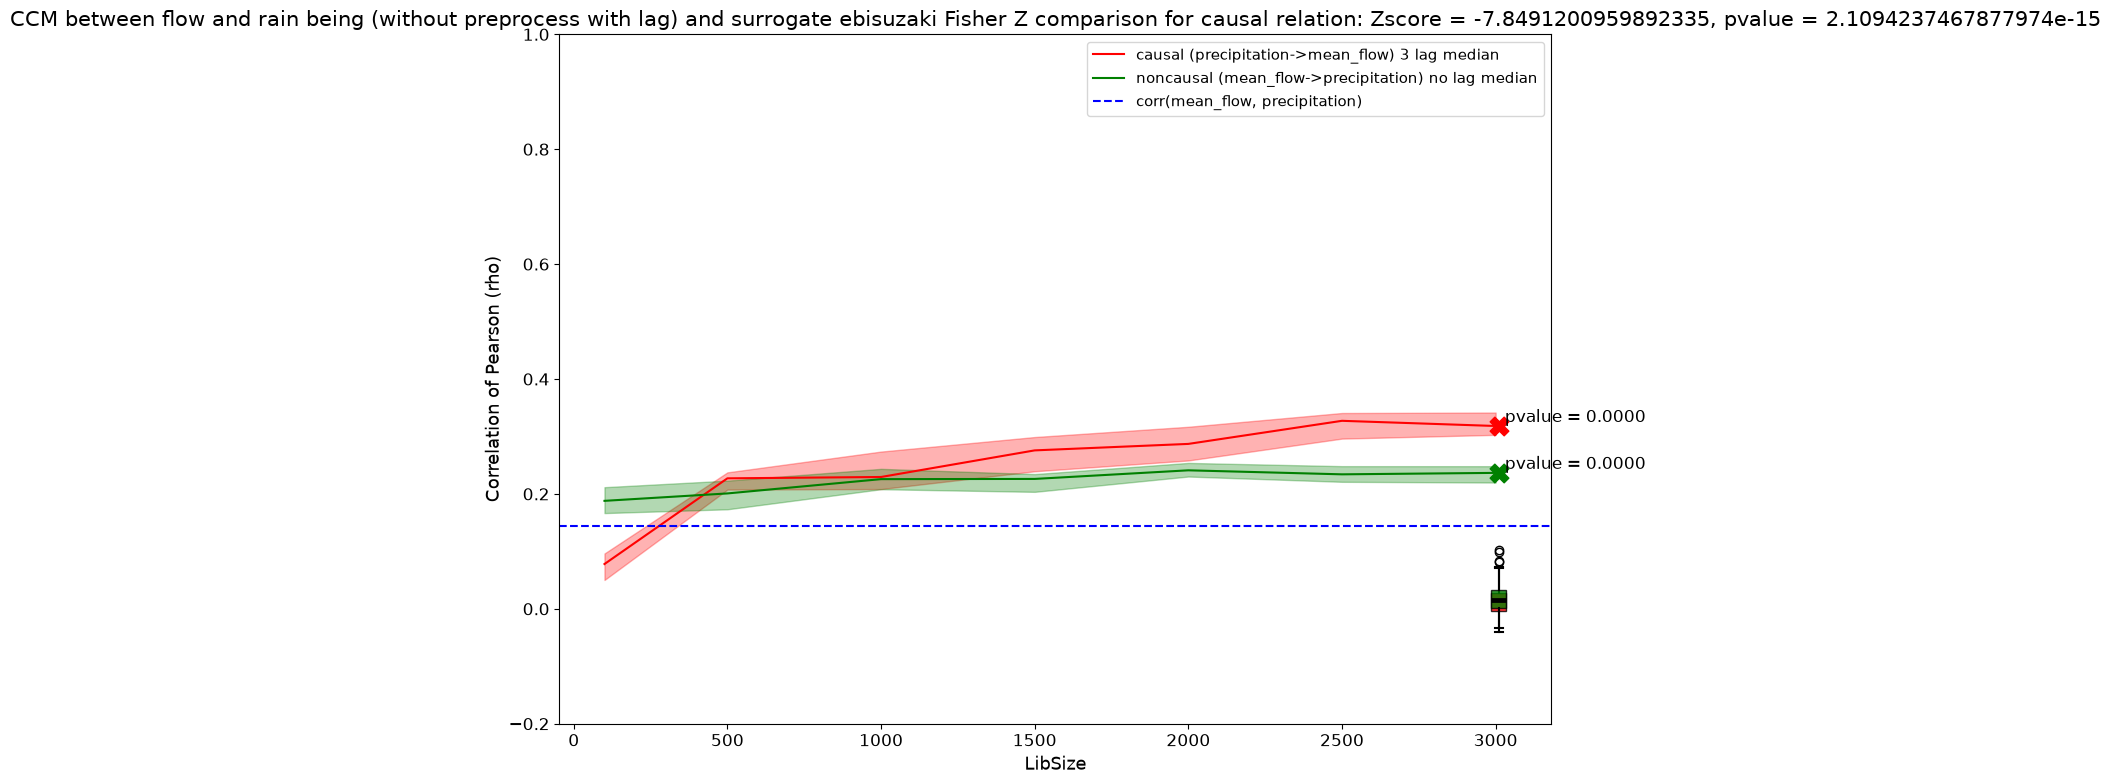

In [ ]:
df = (
    pd.merge(
        meteo[['date', 'precipitation']].dropna(),
        fdv1[['date', 'mean_flow']].dropna(),
        on='date',
        how='inner'
    )
    .sort_values('date')
    .reset_index(drop=True)
)

df = df[['date', 'precipitation', 'mean_flow']].dropna().reset_index(drop=True)

libs = [100, 500, 1000, 1500, 2000, 2500, 3000]

final_causal = fun.final_ccm(df, 'mean_flow', 'precipitation', libs=libs, Tp=-3)
final_noncausal = fun.final_ccm(df, 'precipitation', 'mean_flow', libs=libs, Tp=0)

stat_causal = final_causal[0]
total_causal = stat_causal[0.5].iloc[-1]
stat_noncausal = final_noncausal[0]
total_noncausal = stat_noncausal[0.5].iloc[-1]

lag_mean_flow = pd.Series(list(df['mean_flow'])+ [None,None,None])
lag_precipitation = pd.Series([None,None,None]+list(df['precipitation']))
corr0 = lag_mean_flow.corr(lag_precipitation)

z1 = 0.5 * np.log((1 + corr0)/(1 - corr0))
z2 = 0.5 * np.log((1 + total_causal)/(1 - total_causal))
n = len(lag_mean_flow.dropna())
zobs = (z1-z2) / np.sqrt( 2 / (n-3) )

pval = (1- stats.norm.cdf(abs(zobs))) #https://github.com/MicrosoftResearch/Azimuth/blob/master/azimuth/corrstats.py


surr_causal = fun.surrogate_fast(df, 'mean_flow', 'precipitation', comparaison = total_causal, libs=libs, num=20, Tp=-3, method='ebisuzaki')
surr_noncausal = fun.surrogate_fast(df, 'precipitation', 'mean_flow', comparaison = total_noncausal, libs=libs, num=20, Tp=0, method='ebisuzaki')

pvalue_causal = surr_causal[2]
pvalue_noncausal = surr_noncausal[2]

surresume_causal = surr_causal[1]
surresume_noncausal = surr_noncausal[1]

plt.figure(figsize=(12, 8))
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "legend.fontsize": 11
})

plt.plot(libs, stat_causal[0.5], color='r', label='causal (precipitation->mean_flow) 3 lag median')
plt.fill_between(libs, stat_causal[0.25], stat_causal[0.75], color='r', alpha=0.3)

plt.plot(libs, stat_noncausal[0.5], color='g', label='noncausal (mean_flow->precipitation) no lag median')
plt.fill_between(libs, stat_noncausal[0.25], stat_noncausal[0.75], color='g', alpha=0.3)

plt.axhline(corr0, color='b', linestyle='--', label=f"corr(mean_flow, precipitation)")
# Positionne le boxplot infiltration à len(libsize) + 0.5
plt.boxplot(
    surr_causal[0],
    positions=[libs[-1] + 10],  # ← Décalage ici
    widths=50.0,
    patch_artist=True,
    manage_ticks=False,
    boxprops=dict(facecolor='red', alpha=0.8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5)
)

plt.scatter(libs[-1] + 10, total_causal, color='red', marker='X', s=180, zorder=3)
plt.text(
    libs[-1] + 30,
    total_causal,
    f"pvalue = {pvalue_causal:.4f}",
    va='bottom',
    fontsize=12,
    color='black'
)
plt.boxplot(
    surr_noncausal[0],
    positions=[libs[-1] + 10],  # ← Décalage ici
    widths=50.0,
    patch_artist=True,
    manage_ticks=False,
    boxprops=dict(facecolor='green', alpha=0.8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5)
)

plt.scatter(libs[-1] + 10, total_noncausal, color='green', marker='X', s=180, zorder=3)
plt.text(
    libs[-1] + 30,
    total_noncausal,
    f"pvalue = {pvalue_noncausal:.4f}",
    va='bottom',
    fontsize=12,
    color='black'
)

plt.title(f'CCM between flow and rain being (without preprocess with lag) and surrogate ebisuzaki Fisher Z comparison for causal relation: Zscore = {zobs}, pvalue = {pval}', fontsize=15)
plt.xlabel('LibSize', fontsize=13)
plt.ylabel('Correlation of Pearson (rho)', fontsize=13)
plt.legend(fontsize=11)
plt.ylim(-0.2, 1)
plt.tight_layout()

![title](img/surrogate_rain_ebisuzaki200.png)

    Groundwater <-> stream flow

/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


[surrogate_fast] processed 20/20 surrogates
[surrogate_fast] finished in 383.24s


/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


[surrogate_fast] processed 20/20 surrogates
[surrogate_fast] finished in 391.45s


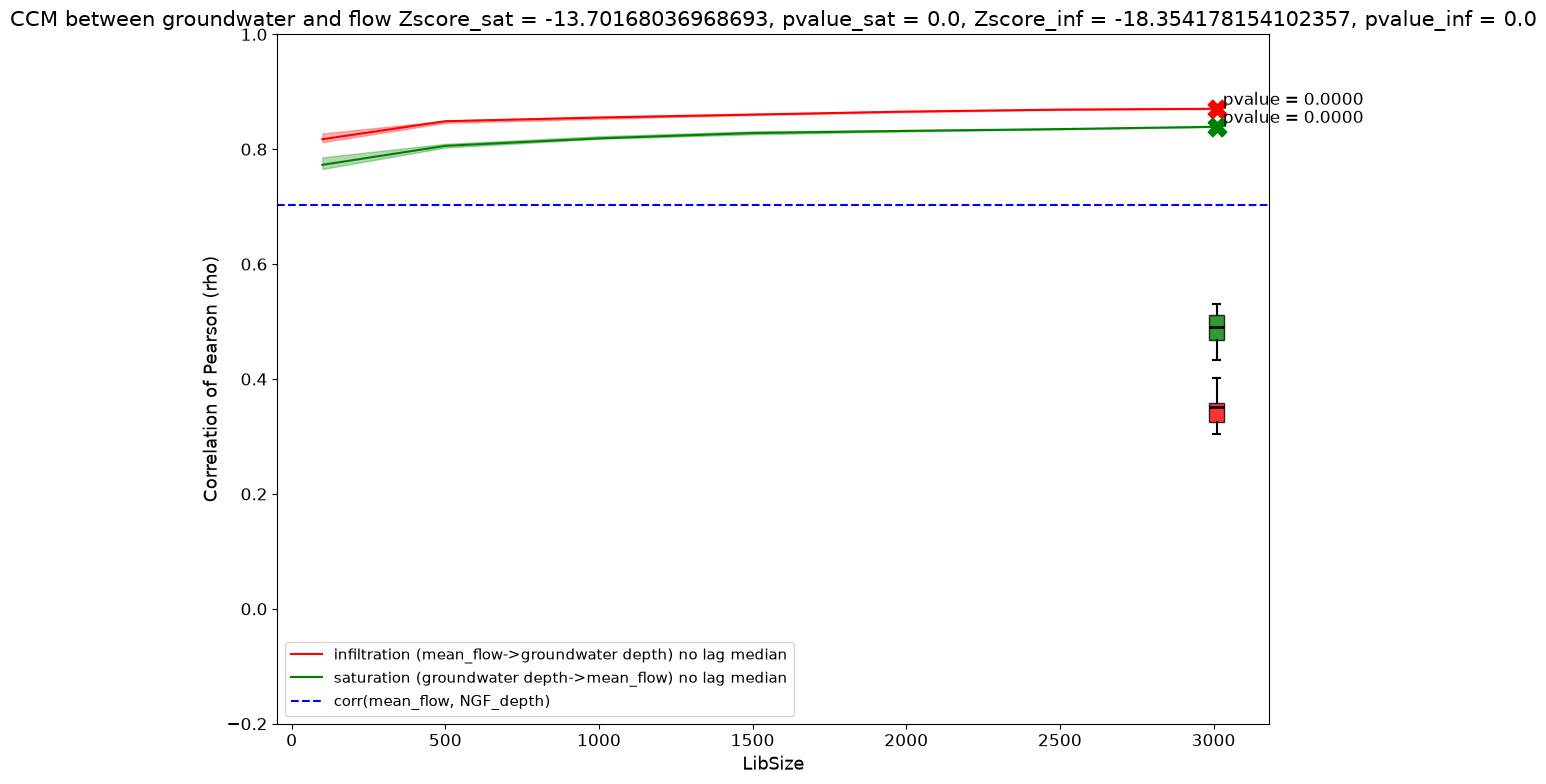

In [ ]:
df = pd.merge(fdv1[['date', 'mean_flow']], ground_water[['date', 'NGF_depth']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df = df[['date', 'mean_flow', 'NGF_depth']].dropna().reset_index(drop=True)

libs = [100, 500, 1000, 1500, 2000, 2500, 3000]

infiltration = fun.final_ccm(df, 'NGF_depth', 'mean_flow', libs=libs, Tp=0)
saturation = fun.final_ccm(df, 'mean_flow', 'NGF_depth', libs=libs, Tp=0)

stat_infiltration = infiltration[0]
total_infiltration = stat_infiltration[0.5].iloc[-1]
stat_saturation = saturation[0]
total_saturation = stat_saturation[0.5].iloc[-1]

corr0 = df['NGF_depth'].corr(df['mean_flow'])

z1 = 0.5 * np.log((1 + corr0)/(1 - corr0))
z2 = 0.5 * np.log((1 + total_saturation)/(1 - total_saturation))
n = len(df['NGF_depth'].dropna())
zobs_sat = (z1-z2) / np.sqrt( 2 / (n-3) )

pval_sat = (1- stats.norm.cdf(abs(zobs_sat)))

z2 = 0.5 * np.log((1 + total_infiltration)/(1 - total_infiltration))
zobs_inf = (z1-z2) / np.sqrt( 2 / (n-3) )

pval_inf = (1- stats.norm.cdf(abs(zobs_inf)))


surr_infiltration = fun.surrogate_fast(df, 'NGF_depth', 'mean_flow', comparaison = total_infiltration, libs=libs, num=20, Tp=-3)
surr_saturation = fun.surrogate_fast(df, 'mean_flow', 'NGF_depth', comparaison = total_saturation, libs=libs, num=20, Tp=0) #200 is better but too long

pvalue_infiltration = surr_infiltration[2]
pvalue_saturation = surr_saturation[2]

surresume_infiltration = surr_infiltration[1]
surresume_saturation = surr_saturation[1]

plt.figure(figsize=(12, 8))
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "legend.fontsize": 11
})

plt.plot(libs, stat_infiltration[0.5], color='r', label='infiltration (mean_flow->groundwater depth) no lag median')
plt.fill_between(libs, stat_infiltration[0.25], stat_infiltration[0.75], color='r', alpha=0.3)

plt.plot(libs, stat_saturation[0.5], color='g', label='saturation (groundwater depth->mean_flow) no lag median')
plt.fill_between(libs, stat_saturation[0.25], stat_saturation[0.75], color='g', alpha=0.3)

plt.axhline(corr0, color='b', linestyle='--', label=f"corr(mean_flow, NGF_depth)")

# Positionne le boxplot infiltration à len(libsize) + 0.5
plt.boxplot(
    surr_infiltration[0],
    positions=[libs[-1] + 10],  # ← Décalage ici
    widths=50.0,
    patch_artist=True,
    manage_ticks=False,
    boxprops=dict(facecolor='red', alpha=0.8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5)
)

# Positionne le boxplot saturation à len(libsize) + 1.5
plt.boxplot(
    surr_saturation[0],
    positions=[libs[-1] + 10],  # ← Décalage ici
    widths=50.0,
    patch_artist=True,
    manage_ticks=False,
    boxprops=dict(facecolor='green', alpha=0.8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5)
)

# Ajuste aussi les positions des scatter points et du texte
plt.scatter(libs[-1] + 10, total_infiltration, color='red', marker='X', s=180, zorder=3)
plt.text(
    libs[-1] + 30,
    total_infiltration,
    f"pvalue = {pvalue_infiltration:.4f}",
    va='bottom',
    fontsize=12,
    color='black'
)

plt.scatter(libs[-1] + 10, total_saturation, color='green', marker='X', s=180, zorder=3)
plt.text(
    libs[-1] + 30,
    total_saturation,
    f"pvalue = {pvalue_saturation:.4f}",
    va='bottom',
    fontsize=12,
    color='black'
)

plt.title(f'CCM between groundwater and flow Zscore_sat = {zobs_sat}, pvalue_sat = {pval_sat}, Zscore_inf = {zobs_inf}, pvalue_inf = {pval_inf}', fontsize=15)
plt.xlabel('LibSize', fontsize=13)
plt.ylabel('Correlation of Pearson (rho)', fontsize=13)
plt.legend(fontsize=11)
plt.ylim(-0.2, 1)
plt.tight_layout()


![title](img/surrogate_groundwater_200.png)

## Different type of embedding for prediction

In [ ]:
df = pd.merge(fdv1[['date', 'mean_flow']], meteo[['date', 'precipitation']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df['lag_precipitation'] = pd.Series([None,None,None]+list(df['precipitation']))
df = pd.merge(df, ground_water[['date', 'NGF_depth']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df = df[['date', 'mean_flow', 'NGF_depth', 'precipitation', 'lag_precipitation']].dropna().reset_index(drop=True)

df = df.copy()
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)
df['date'] = df['date'].dt.strftime('%Y-%m-%d')

print(df)


            date  mean_flow  NGF_depth  precipitation  lag_precipitation
0     2004-01-10   0.714561   0.808164      -0.259135          -0.259135
1     2004-01-12   0.626071   0.808164      -0.259135           0.152659
2     2004-01-13   0.623057   0.855153      -0.259135          -0.259135
3     2004-01-14   0.681045   0.972624      -0.259135          -0.259135
4     2004-01-16   0.687074   0.902142       0.108538          -0.259135
...          ...        ...        ...            ...                ...
3160  2013-11-23  -0.644077  -0.178597      -0.259135           0.196779
3161  2013-11-24  -0.651880  -0.202091      -0.259135          -0.170894
3162  2013-11-25  -0.662077  -0.202091      -0.259135          -0.259135
3163  2013-11-26  -0.670057  -0.225585      -0.244428          -0.259135
3164  2013-11-27  -0.675909  -0.225585      -0.185601          -0.259135

[3165 rows x 5 columns]


    Univariate

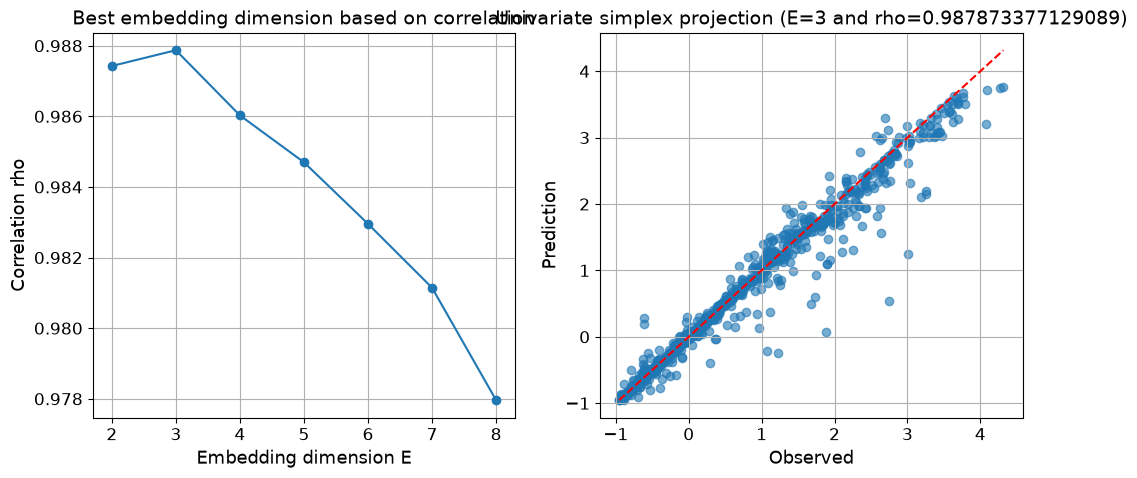

In [ ]:
lib_start = 1
lib_end = len(df) // 2
pred_start = lib_end + 1
pred_end = len(df)

pred_mean_flow, bestE = fun.simplex_prediction(df, 'mean_flow', 'mean_flow', lib=f'{lib_start} {lib_end}', pred=f'{pred_start} {pred_end}')
E_meanflow = fun.evaluate_dimension(df['mean_flow'], lib=f'{lib_start} {lib_end}', pred=f'{pred_start} {pred_end}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(E_meanflow['E'], E_meanflow['rho'], marker='o')
axes[0].set_xlabel("Embedding dimension E")
axes[0].set_ylabel("Correlation rho")
axes[0].set_title("Best embedding dimension based on correlation")
axes[0].grid(True)

pred_mean_flow = pred_mean_flow.dropna(subset=["Predictions", "Observations"])

obs_valid = pred_mean_flow['Observations'].values
pred_valid = pred_mean_flow['Predictions'].values
rho = np.corrcoef(obs_valid, pred_valid)[0, 1]    

axes[1].scatter(obs_valid, pred_valid, alpha=0.6)
axes[1].plot([obs_valid.min(), obs_valid.max()], [obs_valid.min(), obs_valid.max()], 'r--')
axes[1].set_xlabel("Observed")
axes[1].set_ylabel("Prediction")
axes[1].set_title(f"Univariate simplex projection (E={bestE} and rho={rho})")
axes[1].grid(True)


![title](img/univariate.png)

    Multivariate

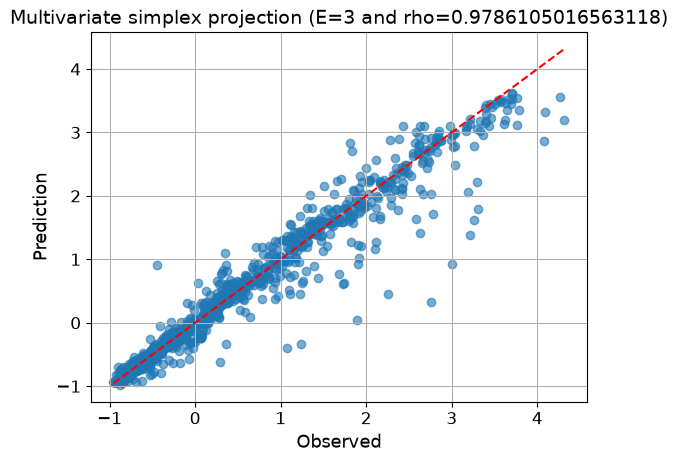

In [ ]:
pred_mean_flow, bestE = fun.simplex_prediction(df, 'mean_flow NGF_depth lag_precipitation', 'mean_flow', lib=f'{lib_start} {lib_end}', pred = f'{pred_start} {pred_end}')
    
plt.figure()

pred_mean_flow = pred_mean_flow.dropna(subset=["Predictions", "Observations"])

obs_valid = pred_mean_flow['Observations'].values
pred_valid = pred_mean_flow['Predictions'].values
rho = np.corrcoef(obs_valid, pred_valid)[0, 1]    

plt.scatter(obs_valid, pred_valid, alpha=0.6)
plt.plot([obs_valid.min(), obs_valid.max()], [obs_valid.min(), obs_valid.max()], 'r--')
plt.xlabel("Observed")
plt.ylabel("Prediction")
plt.title(f"Multivariate simplex projection (E={bestE} and rho={rho})")
plt.grid(True)

![title](img/multivariate.png)

    Multiview

Multiview() Set view sample size to 9


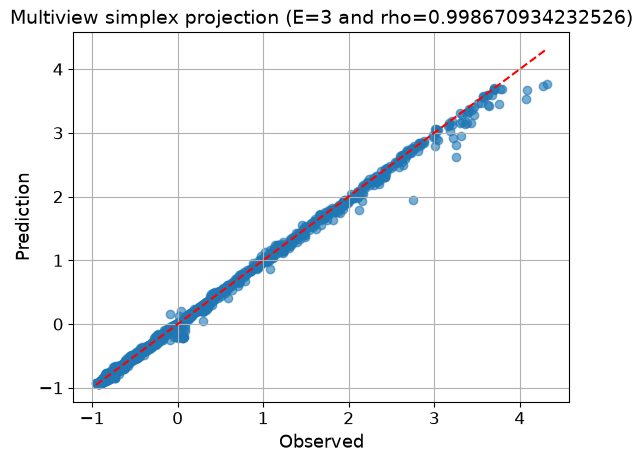

In [ ]:
pred_mean_flow = fun.Multiview(dataFrame = df, columns='mean_flow NGF_depth lag_precipitation', target='mean_flow', lib=f'{lib_start} {lib_end}', pred = f'{pred_start} {pred_end}', E=bestE, Tp=0)['Predictions']

plt.figure()

pred_mean_flow = pred_mean_flow.dropna(subset=["Predictions", "Observations"])

obs_valid = pred_mean_flow['Observations'].values
pred_valid = pred_mean_flow['Predictions'].values
rho = np.corrcoef(obs_valid, pred_valid)[0, 1]    

plt.scatter(obs_valid, pred_valid, alpha=0.6)
plt.plot([obs_valid.min(), obs_valid.max()], [obs_valid.min(), obs_valid.max()], 'r--')
plt.xlabel("Observed")
plt.ylabel("Prediction")
plt.title(f"Multiview simplex projection (E={bestE} and rho={rho})")
plt.grid(True)

![title](img/multiview.png)

## Interaction strenght (where the trouble continues)

The interaction strenght is not weak anymore and results seem more relevant. I still one question on it : why the results are so different between normalized and non normalized data ? Is it normal ? 

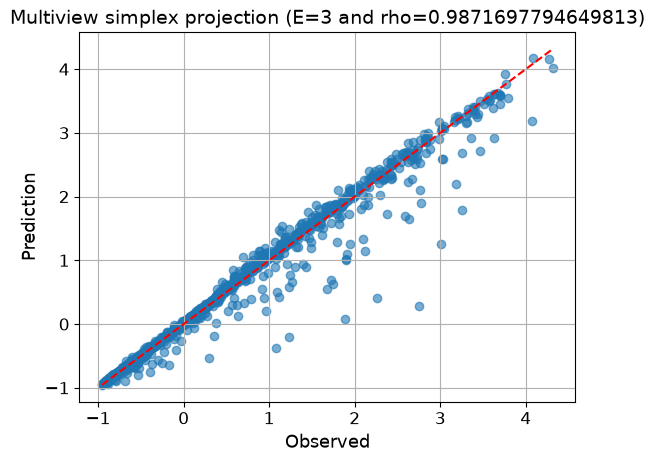

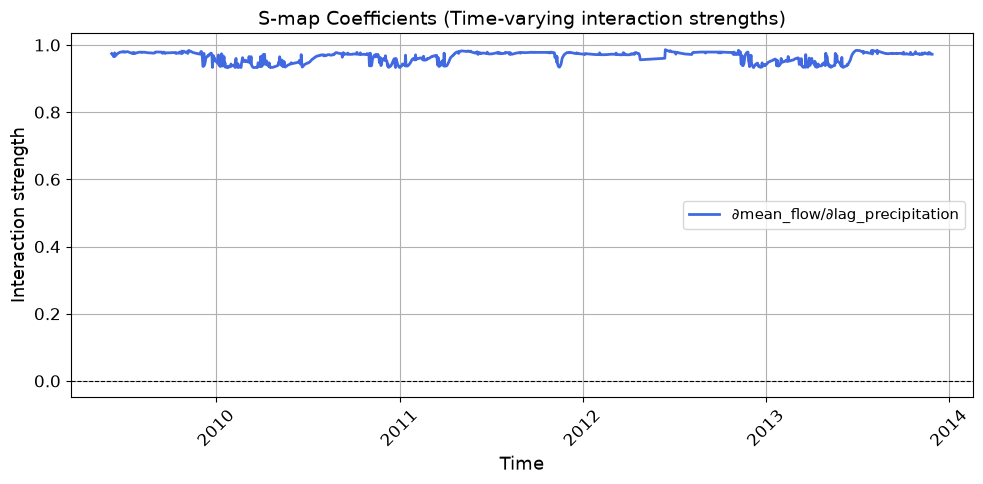

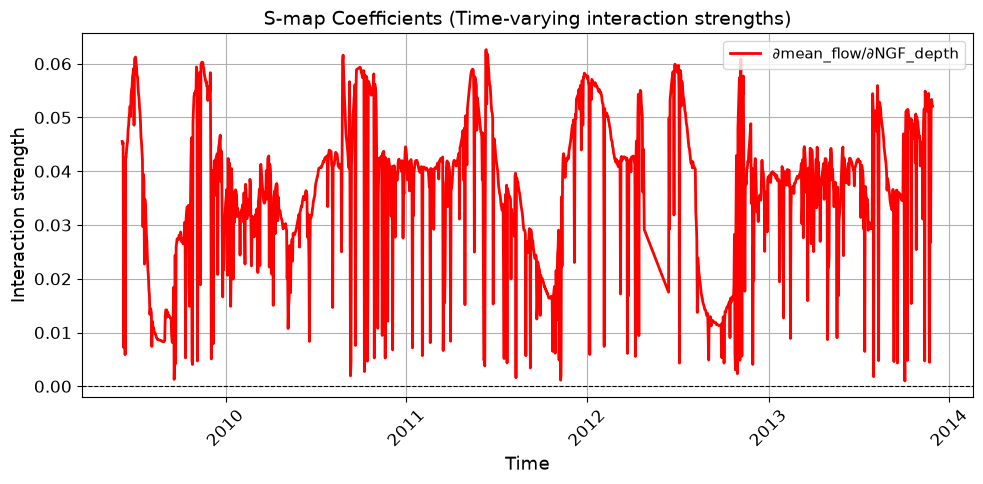

In [ ]:
res_meanflow, best_theta = fun.Smap_prediction(df, "mean_flow lag_precipitation NGF_depth", 'mean_flow', lib=f'{lib_start} {lib_end}', pred = f'{pred_start} {pred_end}')
pred_mean_flow = res_meanflow['predictions']

plt.figure()

pred_mean_flow = pred_mean_flow.dropna(subset=["Predictions", "Observations"])

obs_valid = pred_mean_flow['Observations'].values
pred_valid = pred_mean_flow['Predictions'].values
rho = np.corrcoef(obs_valid, pred_valid)[0, 1]    

plt.scatter(obs_valid, pred_valid, alpha=0.6)
plt.plot([obs_valid.min(), obs_valid.max()], [obs_valid.min(), obs_valid.max()], 'r--')
plt.xlabel("Observed")
plt.ylabel("Prediction")
plt.title(f"Multiview simplex projection (E={bestE} and rho={rho})")
plt.grid(True)

coefficients = res_meanflow['coefficients']

coefficients['date'] = pd.to_datetime(coefficients['date'])

plt.figure(figsize=(10, 5))
plt.plot(coefficients['date'], coefficients['C1'], label='∂mean_flow/∂lag_precipitation', color="royalblue", linewidth=2)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.axhline(0, color="black", linestyle="dashed", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("Interaction strength")
plt.title("S-map Coefficients (Time-varying interaction strengths)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.figure(figsize=(10, 5))
plt.plot(coefficients['date'], coefficients['C2'], label='∂mean_flow/∂NGF_depth', color="red", linewidth=2)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.axhline(0, color="black", linestyle="dashed", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("Interaction strength")
plt.title("S-map Coefficients (Time-varying interaction strengths)")
plt.legend()
plt.grid(True)
plt.tight_layout()


![title](img/interaction_precipitation.png)
![title](img/interaction_groundwater.png)

**With different time steps**

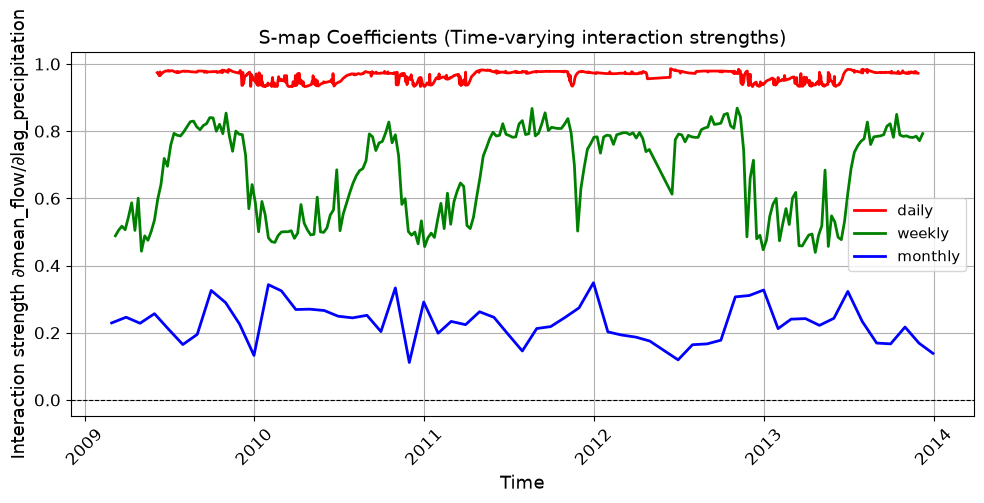

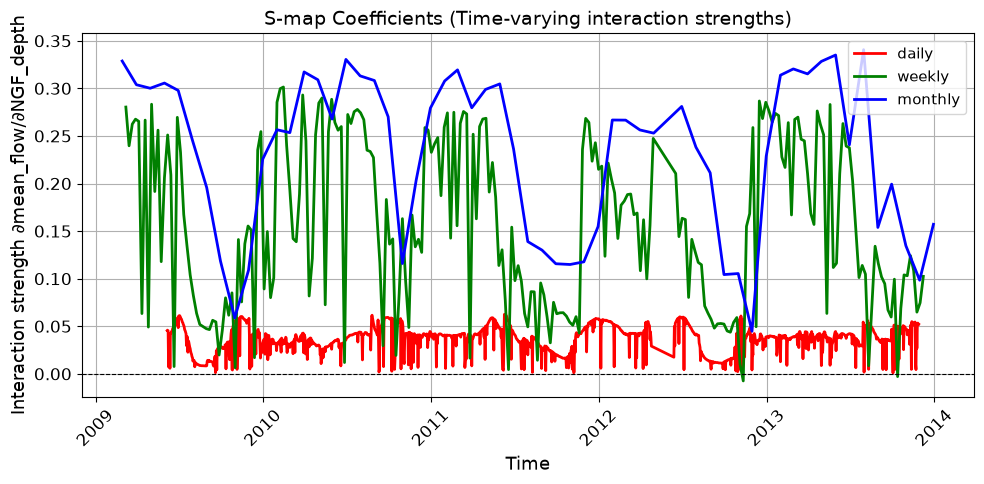

In [ ]:
lib_start_daily = 1
lib_end_daily = len(df) // 2
pred_start_daily = lib_end_daily + 1
pred_end_daily = len(df)
res, best_theta = fun.Smap_prediction(df, "mean_flow lag_precipitation NGF_depth", 'mean_flow', lib=f'{lib_start_daily} {lib_end_daily}', pred = f'{pred_start_daily} {pred_end_daily}')
coefficients= res['coefficients']
coefficients['date'] = pd.to_datetime(coefficients['date'])

df_week = df_week.dropna() 
lib_start_weekly = 1
lib_end_weekly = len(df_week) // 2
pred_start_weekly = lib_end_weekly + 1
pred_end_weekly = len(df_week)
res_week, best_theta = fun.Smap_prediction(df_week, "mean_flow lag_precipitation NGF_depth", 'mean_flow', lib=f'{lib_start_weekly} {lib_end_weekly}', pred = f'{pred_start_weekly} {pred_end_weekly}')
coefficients_week = res_week['coefficients']
coefficients_week['date'] = pd.to_datetime(coefficients_week['date'])

df_month = df_month.dropna() 
lib_start_monthly = 1
lib_end_monthly = len(df_month) // 2
pred_start_monthly = lib_end_monthly + 1
pred_end_monthly= len(df_month)
res_month, best_theta = fun.Smap_prediction(df_month, "mean_flow lag_precipitation NGF_depth", 'mean_flow', lib=f'{lib_start_monthly} {lib_end_monthly}', pred = f'{pred_start_monthly} {pred_end_monthly}')
coefficients_month = res_month['coefficients']
coefficients_month['date'] = pd.to_datetime(coefficients_month['date'])

plt.figure(figsize=(10, 5))
plt.plot(coefficients['date'], coefficients['C1'], label='daily', color="r", linewidth=2)
plt.plot(coefficients_week['date'], coefficients_week['C1'], label='weekly', color="g", linewidth=2)
plt.plot(coefficients_month['date'], coefficients_month['C1'], label='monthly', color="b", linewidth=2)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.axhline(0, color="black", linestyle="dashed", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("Interaction strength ∂mean_flow/∂lag_precipitation")
plt.title("S-map Coefficients (Time-varying interaction strengths)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.figure(figsize=(10, 5))
plt.plot(coefficients['date'], coefficients['C2'], label='daily', color="r", linewidth=2)
plt.plot(coefficients_week['date'], coefficients_week['C2'], label='weekly', color="g", linewidth=2)
plt.plot(coefficients_month['date'], coefficients_month['C2'], label='monthly', color="b", linewidth=2)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.axhline(0, color="black", linestyle="dashed", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("Interaction strength ∂mean_flow/∂NGF_depth")
plt.title("S-map Coefficients (Time-varying interaction strengths)")
plt.legend()
plt.grid(True)
plt.tight_layout()

![title](img/interaction_precipitation_timestep.png)
![title](img/interaction_groundwater_timestep.png)

## Exploration

### Parameter exploration

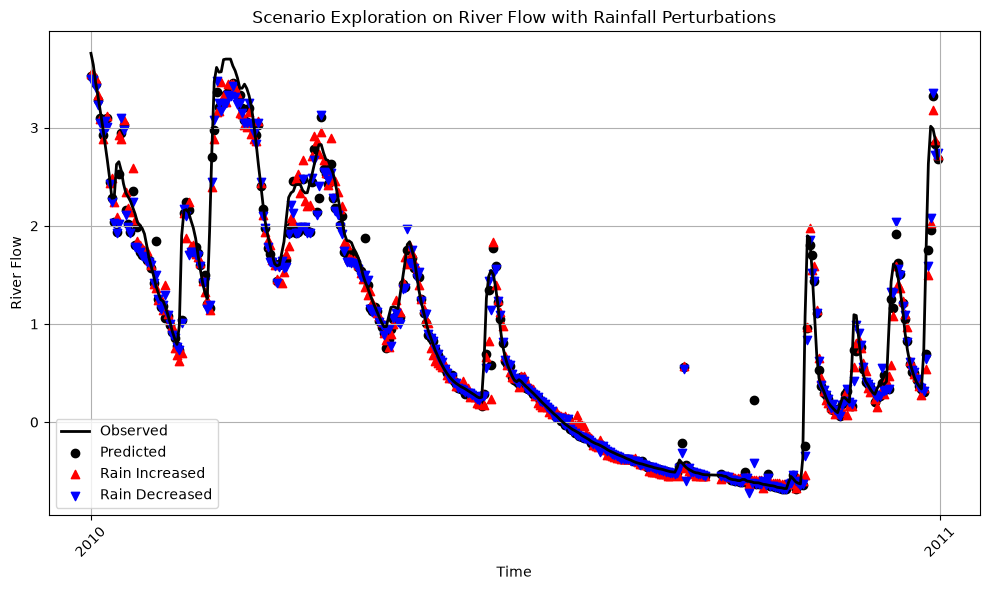

In [ ]:
# 1. Préparation des données (SANS conversion en chaînes)
df = pd.merge(fdv1[['date', 'mean_flow']], meteo[['date', 'precipitation']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df = pd.merge(df, ground_water[['date', 'NGF_depth']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df['lag_precipitation'] = df['precipitation'].shift(3)
df = df[['date', 'mean_flow', 'NGF_depth', 'precipitation', 'lag_precipitation']].dropna().reset_index(drop=True)
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

lib_start = 1
lib_end = len(df) // 2
pred_start = lib_end + 1
pred_end = len(df)
E_best = fun.find_best_E(df, 'mean_flow', 'mean_flow', lib=f'{lib_start} {lib_end}', pred = f'{pred_start} {pred_end}')

flow = df['mean_flow']
rain = df['lag_precipitation']

# 2. Création de lagged avec dates alignées
lag_cols = [f'flow_lag{i}' for i in range(E_best)]
lagged = pd.concat([flow.shift(i) for i in range(E_best)], axis=1)
lagged.columns = lag_cols
lagged['Rain_t'] = df['precipitation'].shift(3).values
start_idx = max(E_best - 1, 3) 
lagged['date'] = df['date'].iloc[start_idx:].reset_index(drop=True)
lagged = lagged.dropna().reset_index(drop=True)

col_names = lag_cols + ['Rain_t']
n_coord = len(col_names)
n0 = len(lagged)
half = n0 // 2

# 3. with_time : garder les dates en datetime
def with_time(d):
    d['date'] = pd.to_datetime(d['date'])  
    d.insert(0, 'time', d['date'])
    d = d.drop(columns=['date'])
    return d

# 4. Exécution
d = lagged.copy()
d.loc[half:, 'Rain_t'] += 0.5
pred_increase = Simplex(dataFrame=with_time(d), lib=f"1 {half}", pred=f"{half+1} {n0}",
                columns=col_names, target=col_names[0], embedded=True,
                E=n_coord, knn=n_coord + 1, verbose=False)

d = lagged.copy()
d.loc[half:, 'Rain_t'] += 0
pred_nochange = Simplex(dataFrame=with_time(d), lib=f"1 {half}", pred=f"{half+1} {n0}",
                columns=col_names, target=col_names[0], embedded=True,
                E=n_coord, knn=n_coord + 1, verbose=False)

d = lagged.copy()
d.loc[half:, 'Rain_t'] += -0.5
pred_decrease = Simplex(dataFrame=with_time(d), lib=f"1 {half}", pred=f"{half+1} {n0}",
                columns=col_names, target=col_names[0], embedded=True,
                E=n_coord, knn=n_coord + 1, verbose=False)


def prep(d):
    d = d.copy()
    d['time'] = pd.to_datetime(d['time'])
    return d[(d['time'] >= '2010-01-01') & (d['time'] <= '2010-12-31')]

pred_nochange, pred_increase, pred_decrease = [prep(d) for d in (pred_nochange, pred_increase, pred_decrease)]

plt.figure(figsize=(10, 6))
plt.plot(pred_nochange['time'], pred_nochange["Observations"].values, label="Observed", color="black", linewidth=2)
plt.scatter(pred_nochange['time'], pred_nochange["Predictions"].values, label="Predicted", color="black", marker='o')
plt.scatter(pred_increase['time'], pred_increase["Predictions"].values, label="Rain Increased", color="red", marker='^')
plt.scatter(pred_decrease['time'], pred_decrease["Predictions"].values, label="Rain Decreased", color="blue", marker='v')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.xlabel("Time")
plt.ylabel("River Flow")
plt.title("Scenario Exploration on River Flow with Rainfall Perturbations")
plt.legend()
plt.grid(True)
plt.tight_layout()

![title](img/exploration_rain.png)

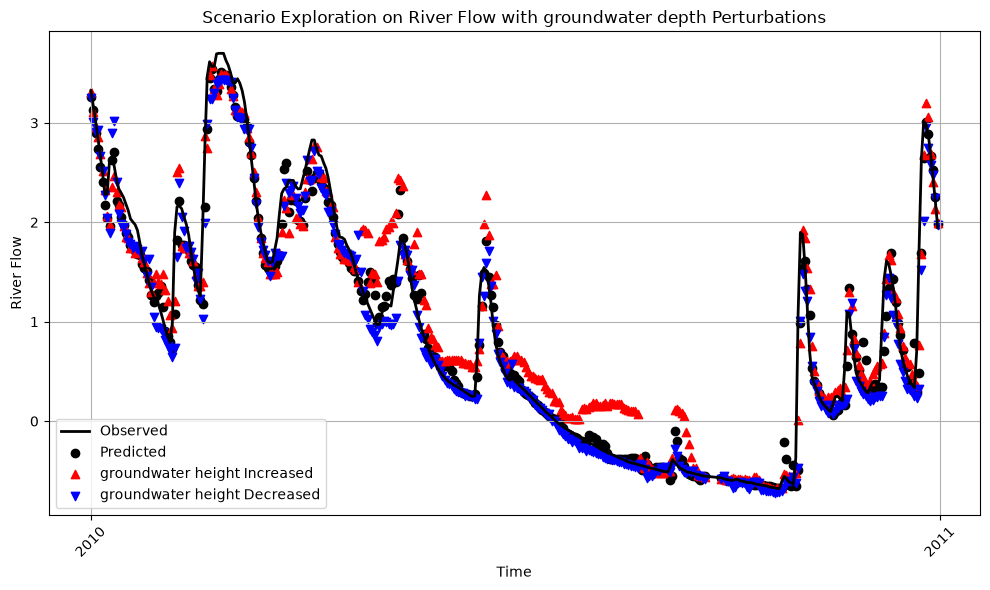

In [ ]:
flow = df['mean_flow']
depth = df['NGF_depth']

# 2. Création de lagged avec dates alignées
lag_cols = [f'flow_lag{i}' for i in range(E_best)]
lagged = pd.concat([flow.shift(i) for i in range(E_best)], axis=1)
lagged.columns = lag_cols
lagged['depth_t'] = depth
lagged['date'] = df['date']
lagged = lagged.dropna().reset_index(drop=True)

col_names = lag_cols + ['depth_t']
n_coord = len(col_names)
n0 = len(lagged)
half = n0 // 2

d = lagged.copy()
d.loc[half:, 'depth_t'] += 0.5
pred_increase = Simplex(dataFrame=with_time(d), lib=f"1 {half}", pred=f"{half+1} {n0}",
                columns=col_names, target=col_names[0], embedded=True,
                E=n_coord, knn=n_coord + 1, verbose=False)

d = lagged.copy()
d.loc[half:, 'depth_t'] += 0
pred_nochange = Simplex(dataFrame=with_time(d), lib=f"1 {half}", pred=f"{half+1} {n0}",
                columns=col_names, target=col_names[0], embedded=True,
                E=n_coord, knn=n_coord + 1, verbose=False)

d = lagged.copy()
d.loc[half:, 'depth_t'] += -0.5
pred_decrease = Simplex(dataFrame=with_time(d), lib=f"1 {half}", pred=f"{half+1} {n0}",
                columns=col_names, target=col_names[0], embedded=True,
                E=n_coord, knn=n_coord + 1, verbose=False)

pred_nochange, pred_increase, pred_decrease = [prep(d) for d in (pred_nochange, pred_increase, pred_decrease)]

plt.figure(figsize=(10, 6))
plt.plot(pred_nochange['time'], pred_nochange["Observations"].values, label="Observed", color="black", linewidth=2)
plt.scatter(pred_nochange['time'], pred_nochange["Predictions"].values, label="Predicted", color="black", marker='o')
plt.scatter(pred_increase['time'], pred_increase["Predictions"].values, label="groundwater height Increased", color="red", marker='^')
plt.scatter(pred_decrease['time'], pred_decrease["Predictions"].values, label="groundwater height Decreased", color="blue", marker='v')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.xlabel("Time")
plt.ylabel("River Flow")
plt.title("Scenario Exploration on River Flow with groundwater depth Perturbations")
plt.legend()
plt.grid(True)
plt.tight_layout()


![title](img/exploration__groundwater.png)

### Tipping point (NLA Algorithm)


In [ ]:
df = pd.merge(fdv1[['date', 'mean_flow']], meteo[['date', 'precipitation']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df = pd.merge(df, ground_water[['date', 'NGF_depth']], on='date', how='inner').sort_values('date').reset_index(drop=True)
df['lag_precipitation'] = df['precipitation'].shift(3)
df = df[['date', 'mean_flow', 'NGF_depth', 'precipitation', 'lag_precipitation']].dropna().reset_index(drop=True)
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

df_nla = df.copy()
df_nla = pd.DataFrame({
    'time': pd.to_datetime(df['date']),  
    'mean_flow': df['mean_flow'].values,
    'lag_precipitation': df['lag_precipitation'].values,
    'NGF_depth': df['NGF_depth'].values
}).dropna()
df_nla['time'] = (df_nla['time'] - pd.Timestamp('1970-01-01')).dt.total_seconds()

n = len(df)
quart = len(df)//4
ref_start = n - quart + 1
ref_end = n
large_start = 1
small_start = quart + quart + 1
end = n-quart
skip_step = 100

nlaObj = CyNLA.nla(df_nla.to_numpy())
nlares = nlaObj.run(FlowRef = f"{ref_start} {ref_end}", LargestLib = f"{large_start} {end}", SmallestLib = f"{small_start} {end}",
                    skipstep = skip_step, numThreads = 1, method = "SMap")
rawS, tilS, trdS = CyNLA.nla.SignalProcessing(nlares, SIGMA = 1)
rawS        = rawS.unstack()
print(rawS)

PicklingError: Can't pickle <cyfunction __SMap at 0x7d067e6f2720>: it's not found as CyNLA.__SMap